<div style="padding: 1.25rem 1.4rem; border-radius: 14px; background: linear-gradient(120deg,#091126,#16284F); color: white;">
  <div style="font-size:0.78rem; letter-spacing:0.12em; text-transform:uppercase; color:#A1E2DD;">Tutorial visual · Ecuaciones diferenciales y computación cuántica</div>
  <h1 style="color:white; margin:0.55rem 0 0.35rem 0;">De una ecuación diferencial a un Hamiltoniano</h1>
  <p style="font-size:1.05rem; color:#E7ECF7; margin:0;">Un ejemplo de dos variables, una rotación y un amortiguamiento.</p>
</div>

En este notebook veremos cómo una parte de la evolución de un sistema diferencial lineal puede reproducirse mediante la evolución de un estado cuántico.

**La idea que queremos llevarnos:** codificamos las variables en las amplitudes de un estado, construimos un Hamiltoniano que genera la dinámica adecuada y utilizamos simulación hamiltoniana para evolucionarlo.

No vamos a estudiar computación cuántica en general. Introduciremos únicamente los conceptos necesarios para seguir este ejemplo.

> **Qué vamos a demostrar y qué no.** El ejemplo mostrará una correspondencia matemática exacta para la parte rotacional del sistema. El amortiguamiento, en este caso particular, se aplicará después mediante un factor clásico. Esto es una demostración didáctica, no una demostración de ventaja cuántica.

## 0. Preparación

Necesitamos únicamente `NumPy` y `Matplotlib` para las matemáticas y las visualizaciones. En la segunda mitad utilizaremos Qiskit para representar la evolución cuántica.

Si todavía no tienes Qiskit instalado, ejecuta en una celda de terminal o en una celda del notebook:

```bash
python -m pip install "qiskit>=2,<3" ipywidgets
```

En Google Colab también puedes ejecutar `%pip install "qiskit>=2,<3" ipywidgets` en una celda. `ipywidgets` activa los controles interactivos; si no está instalado, el notebook sigue funcionando con las gráficas estáticas.

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Parámetros del ejemplo. Puedes modificarlos y volver a ejecutar el notebook.
omega = 1.0       # velocidad angular
gamma = 0.12     # intensidad del amortiguamiento

In [20]:
# Tiempo de simulación y condición inicial.
t_max = 4 * np.pi
t_demo = np.pi / 3
x0 = np.array([1.0, 0.0])

# Matrices que definen la dinámica.
A_rotation = np.array([
    [0.0, -omega],
    [omega,  0.0],
])
A_damping = -gamma * np.eye(2)
A = A_rotation + A_damping

print("Matriz A =")
print(A)
print(f"\nParámetros: omega = {omega:.2f}, gamma = {gamma:.2f}")
print(f"Condición inicial: x(0) = {x0}")

Matriz A =
[[-0.12 -1.  ]
 [ 1.   -0.12]]

Parámetros: omega = 1.00, gamma = 0.12
Condición inicial: x(0) = [1. 0.]


## 1. El problema clásico: un punto que gira y se amortigua

Consideremos el sistema de ecuaciones diferenciales

$$
\boxed{\dot{\mathbf{x}}=A\mathbf{x}},\qquad
\mathbf{x}(0)=\begin{pmatrix}1\\0\end{pmatrix},
$$

con

$$
A=\begin{pmatrix}-\gamma&-\omega\\
\omega&-\gamma\end{pmatrix}.
$$

Escrito componente a componente:

$$
\begin{aligned}
\dot{x}_1&=-\gamma x_1-\omega x_2,\\
\dot{x}_2&=\omega x_1-\gamma x_2.
\end{aligned}
$$

Podemos interpretar $\mathbf{x}(t)=(x_1(t),x_2(t))$ como la posición de un punto en el plano. El parámetro $\omega$ hace que el punto gire, mientras que $\gamma$ hace que se acerque al origen.

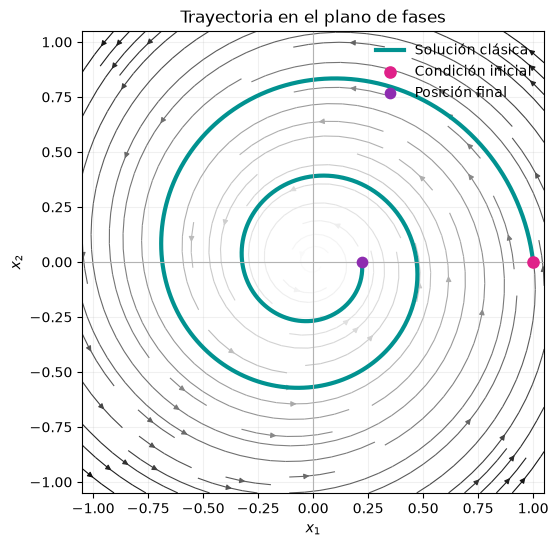

In [21]:
# Solución exacta del sistema para x(0) = (1, 0).
def classical_solution(t, omega=omega, gamma=gamma):
    """Devuelve x(t) para la condición inicial x(0) = (1, 0)."""
    t = np.asarray(t)
    decay = np.exp(-gamma * t)
    return np.stack((decay * np.cos(omega * t),
                     decay * np.sin(omega * t)), axis=-1)


# Campo vectorial y trayectoria.
times = np.linspace(0.0, t_max, 700)
trajectory = classical_solution(times)

fig, ax = plt.subplots(figsize=(7.6, 6.0))
xx = np.linspace(-1.05, 1.05, 17)
yy = np.linspace(-1.05, 1.05, 17)
X, Y = np.meshgrid(xx, yy)
U = -gamma * X - omega * Y
V = omega * X - gamma * Y
speed = np.sqrt(U**2 + V**2)
ax.streamplot(X, Y, U, V, color=speed, cmap="Greys", density=1.0,
              linewidth=0.8, arrowsize=0.8, minlength=0.08)
ax.plot(trajectory[:, 0], trajectory[:, 1], color="#019290", lw=3,
        label="Solución clásica")
ax.scatter([x0[0]], [x0[1]], color="#E02189", s=65, zorder=5,
           label="Condición inicial")
ax.scatter([trajectory[-1, 0]], [trajectory[-1, 1]], color="#8E2DB0", s=55,
           zorder=5, label="Posición final")
ax.axhline(0, color="0.7", lw=0.8)
ax.axvline(0, color="0.7", lw=0.8)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_title("Trayectoria en el plano de fases")
ax.legend(frameon=False, loc="upper right")
ax.grid(alpha=0.18)
plt.show()

### ¿Qué nos está diciendo la matriz?

La matriz se puede separar en dos partes:

$$
A=\underbrace{\begin{pmatrix}0&-\omega\\\omega&0\end{pmatrix}}_{A_{\rm rot}:\;\text{rotación}}
-\underbrace{\gamma\begin{pmatrix}1&0\\0&1\end{pmatrix}}_{\text{amortiguamiento}}.
$$

La solución exacta es

$$
\boxed{\mathbf{x}(t)=e^{-\gamma t}
\begin{pmatrix}\cos(\omega t)\\\sin(\omega t)\end{pmatrix}.}
$$

El primer factor reduce la longitud del vector. El seno y el coseno determinan su dirección.

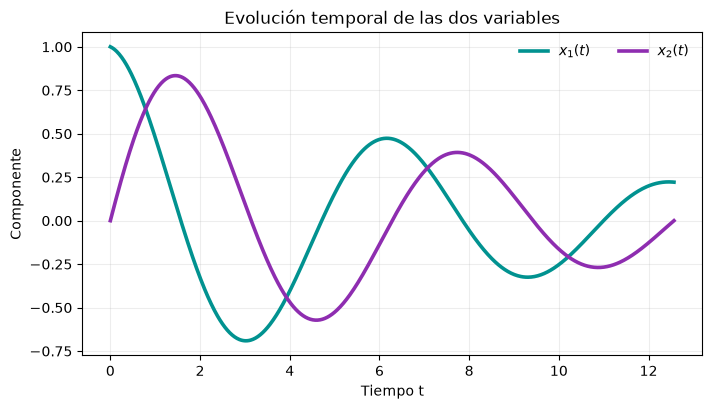

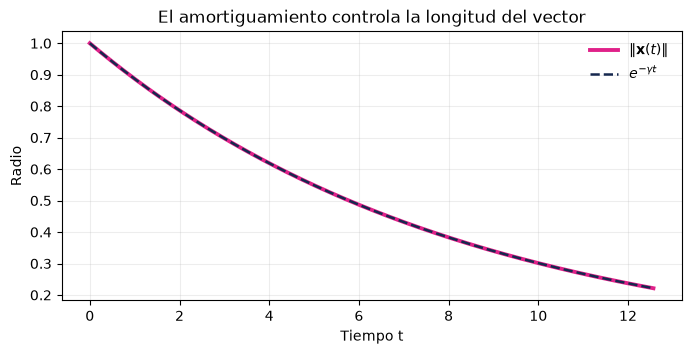

In [22]:
# Las dos componentes como funciones del tiempo.
fig, ax = plt.subplots(figsize=(8.0, 4.2))
ax.plot(times, trajectory[:, 0], color="#019290", lw=2.6, label=r"$x_1(t)$")
ax.plot(times, trajectory[:, 1], color="#8E2DB0", lw=2.6, label=r"$x_2(t)$")
ax.set_xlabel("Tiempo t")
ax.set_ylabel("Componente")
ax.set_title("Evolución temporal de las dos variables")
ax.grid(alpha=0.22)
ax.legend(frameon=False, ncol=2)
plt.show()

# Comprobación visual: el radio decae exponencialmente.
radius = np.linalg.norm(trajectory, axis=1)
fig, ax = plt.subplots(figsize=(8.0, 3.5))
ax.plot(times, radius, color="#E02189", lw=2.8, label=r"$\|\mathbf{x}(t)\|$")
ax.plot(times, np.exp(-gamma * times), color="#16284F", ls="--", lw=1.8,
        label=r"$e^{-\gamma t}$")
ax.set_xlabel("Tiempo t")
ax.set_ylabel("Radio")
ax.set_title("El amortiguamiento controla la longitud del vector")
ax.grid(alpha=0.22)
ax.legend(frameon=False)
plt.show()

### Una observación importante

El ejemplo es sencillo porque el amortiguamiento afecta por igual a las dos componentes: es proporcional a la matriz identidad. Por eso podemos separar la solución en una rotación y un factor de decaimiento común.

A continuación nos centraremos en la parte rotacional. Es la que vamos a reproducir con la evolución de un estado cuántico.

## 2. De un vector clásico a un estado cuántico

Un sistema cuántico de dos niveles se puede describir mediante dos amplitudes complejas:

$$
|\psi\rangle=\alpha|0\rangle+\beta|1\rangle
\quad\longleftrightarrow\quad
\begin{pmatrix}\alpha\\\beta\end{pmatrix}.
$$

Para seguir el ejemplo, basta con pensar en el estado cuántico como un vector de dos componentes. Vamos a asociar las dos variables clásicas con las dos amplitudes:

$$
\begin{pmatrix}x_1\\x_2\end{pmatrix}
\quad\longleftrightarrow\quad
|\psi\rangle= x_1|0\rangle+x_2|1\rangle.
$$

Hay una diferencia importante: las amplitudes de un estado cuántico normalizado deben cumplir

$$
|\alpha|^2+|\beta|^2=1.
$$

Nuestra condición inicial $\mathbf{x}(0)=(1,0)^T$ ya cumple esta condición. Por tanto, podemos empezar con el estado $|\psi(0)\rangle=|0\rangle$.

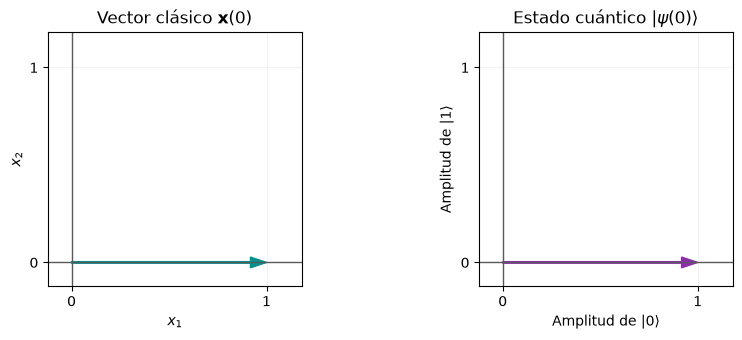

In [23]:
# Dibujo esquemático: las dos entradas del vector se asocian a las dos amplitudes.
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.5))
for ax in axes:
    ax.set_xlim(-0.12, 1.18)
    ax.set_ylim(-0.12, 1.18)
    ax.axhline(0, color="0.35", lw=1)
    ax.axvline(0, color="0.35", lw=1)
    ax.set_aspect("equal")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.grid(alpha=0.15)

axes[0].arrow(0, 0, 1, 0, width=0.008, head_width=0.055,
              length_includes_head=True, color="#019290")
axes[0].set_xlabel(r"$x_1$")
axes[0].set_ylabel(r"$x_2$")
axes[0].set_title(r"Vector clásico $\mathbf{x}(0)$")

axes[1].arrow(0, 0, 1, 0, width=0.008, head_width=0.055,
              length_includes_head=True, color="#8E2DB0")
axes[1].set_xlabel(r"Amplitud de $|0\rangle$")
axes[1].set_ylabel(r"Amplitud de $|1\rangle$")
axes[1].set_title(r"Estado cuántico $|\psi(0)\rangle$")
plt.tight_layout()
plt.show()

> **La asociación que utilizamos:** las dos componentes reales del vector clásico serán las dos amplitudes del estado cuántico. En este ejemplo concreto se mantienen reales durante toda la evolución.

No estamos diciendo que un vector clásico y un estado cuántico sean lo mismo en todos los sentidos. Estamos aprovechando que ambos se pueden representar mediante dos componentes y que, para esta dinámica, sus ecuaciones de evolución coinciden.

## 3. Construir el Hamiltoniano

La parte rotacional del sistema clásico es

$$
\frac{d}{dt}|\psi(t)\rangle=
\underbrace{\begin{pmatrix}0&-\omega\\\omega&0\end{pmatrix}}_{A_{\rm rot}}
|\psi(t)\rangle.
$$

La ecuación de Schrödinger para un sistema cuyo Hamiltoniano no depende del tiempo es

$$
i\hbar\frac{d}{dt}|\psi(t)\rangle=H|\psi(t)\rangle.
$$

Multiplicamos nuestra ecuación rotacional por $i\hbar$ y comparamos ambas expresiones:

$$
H=i\hbar A_{\rm rot}
=\hbar\omega\begin{pmatrix}0&-i\\i&0\end{pmatrix}.
$$

La matriz que aparece es la matriz de Pauli $Y$, que denotaremos por $\sigma_y$. Así que

$$
\boxed{H=\hbar\omega\sigma_y.}
$$

**Ya tenemos el Hamiltoniano que necesitamos.** Su evolución cuántica reproduce exactamente la parte rotacional de nuestro sistema diferencial.

In [24]:
# Comprobamos la relación entre la matriz original de rotación y el Hamiltoniano.
pauli_y = np.array([[0.0, -1.0j], [1.0j, 0.0j]])
H_over_hbar = omega * pauli_y  # Trabajamos con hbar = 1 en el código.


### ¿Por qué podemos llamarlo Hamiltoniano?

Un Hamiltoniano debe ser una matriz **hermítica**. En este caso se cumple porque la matriz de rotación es antisimétrica y tiene entradas reales. No hace falta profundizar más en esta propiedad para seguir el tutorial: nos garantiza que la evolución que estamos construyendo es una evolución cuántica válida.

**Matiz importante:** no hemos convertido toda la matriz $A$ en un Hamiltoniano. Hemos convertido únicamente la parte rotacional. El término $-\gamma I$ produce amortiguamiento, mientras que una evolución hamiltoniana conserva la norma del estado.

## 4. Simulación hamiltoniana: dejar evolucionar el estado

Una vez conocido el Hamiltoniano, la evolución del estado viene dada por

$$
|\psi(t)\rangle= e^{-iHt/\hbar}|\psi(0)\rangle.
$$

A esta operación la llamamos **simulación hamiltoniana**: implementar la evolución que genera un Hamiltoniano durante un intervalo de tiempo.

En nuestro caso,

$$
|\psi(t)\rangle=e^{-i\omega t\sigma_y}|0\rangle.
$$

Al aplicar la exponencial obtenemos

$$
\boxed{|\psi(t)\rangle=
\begin{pmatrix}\cos(\omega t)\\\sin(\omega t)\end{pmatrix}.}
$$

¡Es exactamente la misma rotación que aparece en la solución clásica!

In [25]:
# Evolución cuántica calculada directamente con matrices.
def quantum_solution_exact(t, omega=omega):
    """Estado cuántico ideal para el estado inicial |0> y H/hbar = omega * sigma_y."""
    return np.array([np.cos(omega * t), np.sin(omega * t)], dtype=complex)


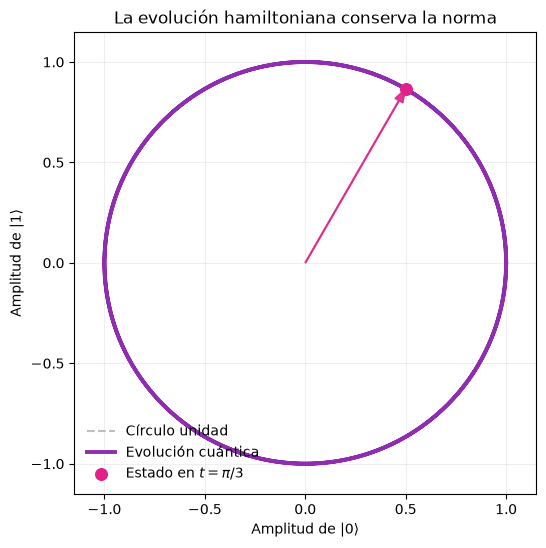

In [26]:
# Trayectoria de las amplitudes. Sin amortiguamiento, el vector gira sobre el círculo unidad.
psi_path = np.array([quantum_solution_exact(t, omega) for t in times])

fig, ax = plt.subplots(figsize=(6.6, 6.0))
angle = np.linspace(0, 2*np.pi, 400)
ax.plot(np.cos(angle), np.sin(angle), color="0.75", ls="--", lw=1.5,
        label="Círculo unidad")
ax.plot(psi_path[:, 0].real, psi_path[:, 1].real, color="#8E2DB0", lw=2.8,
        label="Evolución cuántica")
ax.scatter([psi_demo_exact[0].real], [psi_demo_exact[1].real],
           color="#E02189", s=70, zorder=5, label=r"Estado en $t=\pi/3$")
ax.arrow(0, 0, psi_demo_exact[0].real, psi_demo_exact[1].real,
         width=0.004, head_width=0.045, color="#E02189",
         length_includes_head=True, alpha=0.9)
ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-1.15, 1.15)
ax.set_ylim(-1.15, 1.15)
ax.set_xlabel(r"Amplitud de $|0\rangle$")
ax.set_ylabel(r"Amplitud de $|1\rangle$")
ax.set_title("La evolución hamiltoniana conserva la norma")
ax.grid(alpha=0.2)
ax.legend(frameon=False, loc="lower left")
plt.show()

### Interpretación

El estado cuántico gira, pero su longitud permanece igual a uno:

$$
|\alpha(t)|^2+|\beta(t)|^2=1.
$$

Por eso la evolución hamiltoniana representa la rotación, pero no el amortiguamiento. Volveremos a introducir el factor de amortiguamiento cuando reconstruyamos la solución completa.

## 5. Implementar la evolución con Qiskit

Ahora utilizaremos Qiskit para construir el circuito que representa la evolución.

No necesitamos aprender Qiskit desde cero. Solo utilizaremos tres objetos:

- `QuantumCircuit`: contiene las operaciones que aplicamos al qubit.
- `SparsePauliOp`: representa el Hamiltoniano usando matrices de Pauli.
- `PauliEvolutionGate`: representa la evolución $e^{-itK}$ generada por un operador $K$.

En Qiskit trabajaremos con $\hbar=1$, por lo que el operador que introducimos es

$$
K=H/\hbar=\omega\sigma_y.
$$

La operación que queremos aplicar es, por tanto,

$$
U(t)=e^{-it\omega\sigma_y}.
$$

In [27]:
# Qiskit es opcional para ejecutar la parte matemática del notebook.
# Si no está instalado, ejecuta: %pip install "qiskit>=2,<3"
import qiskit
from qiskit import QuantumCircuit
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import SparsePauliOp, Statevector
print(f"Qiskit disponible. Versión: {qiskit.__version__}")

Qiskit disponible. Versión: 2.6.2


In [32]:
# K = H/hbar = omega * sigma_y.
hamiltonian = SparsePauliOp("Y", coeffs=[omega])

# Definimos la evolución U(t) = exp(-i * t * K).
evolution = PauliEvolutionGate(
    hamiltonian,
    time=t_demo,
    label="Evolución hamiltoniana",
)

# El qubit empieza en |0> por defecto.
circuit = QuantumCircuit(1)
circuit.append(evolution, [0])

print(circuit.draw(output="text"))

   ┌─────────────────────────────┐
q: ┤ Evolución hamiltoniana(π/3) ├
   └─────────────────────────────┘


El circuito contiene una sola operación de evolución. Para este ejemplo de un único término de Pauli, la operación corresponde a una rotación alrededor del eje $Y$. No necesitamos descomponerla en puertas elementales para entender la demostración.

> `PauliEvolutionGate` es una representación de alto nivel de la evolución. En una ejecución sobre hardware, Qiskit tendría que compilarla a operaciones disponibles en ese dispositivo. Aquí utilizaremos un simulador ideal para centrarnos en las amplitudes.

## 6. Obtener las amplitudes y reconstruir la solución

Un simulador de vector de estado permite calcular directamente las amplitudes del estado final. En un ordenador cuántico real no podemos simplemente leer todas las amplitudes de una vez: se estiman mediante mediciones, y eso introduce consideraciones adicionales.

Para la demostración usaremos `Statevector`, que aplica el circuito al estado inicial $|0\rangle$ y devuelve el vector de amplitudes.

In [33]:
# Evolución ideal del circuito en el simulador de vector de estado.
state = Statevector.from_instruction(circuit)
psi_qiskit = np.asarray(state.data, dtype=complex)

# Resultado analítico con el que comparamos.
psi_exact = quantum_solution_exact(t_demo)

print("Amplitudes devueltas por Qiskit:")
print(psi_qiskit)
print("\nAmplitudes analíticas:")
print(psi_exact)
print(f"\nError máximo: {np.max(np.abs(psi_qiskit - psi_exact)):.3e}")
print(f"Norma del estado: {np.linalg.norm(psi_qiskit):.12f}")

assert np.allclose(psi_qiskit, psi_exact, atol=1e-10)

Amplitudes devueltas por Qiskit:
[0.5      +0.j 0.8660254+0.j]

Amplitudes analíticas:
[0.5      +0.j 0.8660254+0.j]

Error máximo: 0.000e+00
Norma del estado: 1.000000000000


### Recuperar el amortiguamiento

La solución clásica completa era

$$
\mathbf{x}(t)=e^{-\gamma t}
\begin{pmatrix}\cos(\omega t)\\\sin(\omega t)\end{pmatrix}.
$$

El estado cuántico contiene la parte rotacional. Por tanto, recuperamos la solución completa multiplicando sus amplitudes por el factor clásico de amortiguamiento:

$$
\boxed{\mathbf{x}(t)=e^{-\gamma t}|\psi(t)\rangle.}
$$

En este ejemplo, el factor se puede calcular fácilmente porque el amortiguamiento es el mismo para las dos componentes.

In [34]:
# El estado cuántico contiene la rotación; el factor e^(-gamma*t) restaura el radio.
x_reconstructed = np.exp(-gamma * t_demo) * psi_qiskit.real
x_classical_exact = classical_solution(t_demo)

print("Solución reconstruida a partir de Qiskit:")
print(x_reconstructed)
print("\nSolución clásica exacta:")
print(x_classical_exact)
print(f"\nError máximo: {np.max(np.abs(x_reconstructed - x_classical_exact)):.3e}")

assert np.allclose(x_reconstructed, x_classical_exact, atol=1e-10)

Solución reconstruida a partir de Qiskit:
[0.44095569 0.76375766]

Solución clásica exacta:
[0.44095569 0.76375766]

Error máximo: 0.000e+00


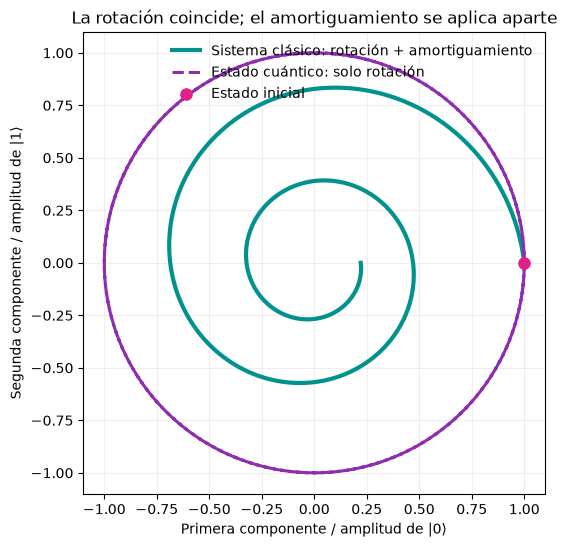

In [31]:
# Comparamos las trayectorias completas: clásica amortiguada y cuántica sin amortiguamiento.
classical_path = classical_solution(times)
quantum_path = np.array([quantum_solution_exact(t, omega).real for t in times])

fig, ax = plt.subplots(figsize=(7.2, 6.0))
ax.plot(classical_path[:, 0], classical_path[:, 1], color="#019290", lw=3,
        label="Sistema clásico: rotación + amortiguamiento")
ax.plot(quantum_path[:, 0], quantum_path[:, 1], color="#8E2DB0", lw=2.2,
        ls="--", label="Estado cuántico: solo rotación")
ax.scatter([1], [0], color="#E02189", s=65, zorder=5, label="Estado inicial")
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel(r"Primera componente / amplitud de $|0\rangle$")
ax.set_ylabel(r"Segunda componente / amplitud de $|1\rangle$")
ax.set_title("La rotación coincide; el amortiguamiento se aplica aparte")
ax.grid(alpha=0.2)
ax.legend(frameon=False, loc="upper right")
plt.show()

## 7. ¿Qué hemos demostrado?

Para este sistema particular hemos seguido cinco pasos:

1. Partimos de una ecuación diferencial lineal: $\dot{\mathbf{x}}=A\mathbf{x}$.
2. Separamos la matriz en rotación y amortiguamiento.
3. Asociamos las dos componentes con las amplitudes de un qubit.
4. Construimos el Hamiltoniano $H=\hbar\omega\sigma_y$ y simulamos su evolución.
5. Recuperamos la solución clásica completa aplicando el factor $e^{-\gamma t}$.

La conexión principal es

$$
\boxed{\text{Dinámica diferencial rotacional}\;\longleftrightarrow\;
\text{evolución hamiltoniana}.}
$$

## 8. ¿Y si el sistema tiene muchas variables?

Para un vector de $N$ componentes, una posible codificación es

$$
|\psi\rangle=\sum_{j=0}^{N-1}x_j|j\rangle,
$$

suponiendo que el vector se ha normalizado. Un registro de $n$ qubits tiene $2^n$ amplitudes, por lo que puede representar un vector de dimensión $N\leq 2^n$ (rellenando con ceros si hace falta).

Esto sugiere una posibilidad interesante: representar vectores de dimensión grande mediante un número relativamente pequeño de qubits y utilizar evoluciones cuánticas para procesarlos.

Pero hay tres preguntas que no podemos ignorar:

- **Preparación:** ¿podemos cargar el vector inicial de manera eficiente?
- **Hamiltoniano:** ¿podemos construir e implementar eficientemente el Hamiltoniano que representa la dinámica?
- **Lectura:** ¿qué información necesitamos recuperar y cuántas mediciones hacen falta para estimarla?

Por tanto, que un estado tenga $2^n$ amplitudes no significa que podamos leer $2^n$ números de forma gratuita. La preparación y la extracción de información son parte esencial del coste del algoritmo.

> **Mensaje final:** la simulación hamiltoniana ofrece una forma de reproducir ciertas dinámicas diferenciales mediante la evolución de estados cuánticos. Encontrar la correspondencia matemática es solo el primer paso; para obtener una ventaja práctica también hay que resolver eficientemente la preparación del estado, la implementación del Hamiltoniano y la lectura del resultado.

---

### Referencias y documentación

- IBM Quantum, [PauliEvolutionGate](https://qiskit.qotlabs.org/docs/api/qiskit/qiskit.circuit.library.PauliEvolutionGate). Define la evolución $U(t)=e^{-itH}$ para operadores hermíticos expresados mediante matrices de Pauli.
- IBM Quantum, [Statevector](https://qiskit.qotlabs.org/docs/api/qiskit/qiskit.quantum_info.Statevector). Herramienta de Qiskit para representar y evolucionar vectores de estado en simulación ideal.
- IBM Quantum, [Instalación de Qiskit](https://qiskit.qotlabs.org/docs/guides/install-qiskit).

**Nota sobre el alcance:** el ejemplo utiliza un qubit y una matriz con una estructura especialmente sencilla. No demuestra una ventaja cuántica frente a métodos clásicos ni constituye un método general para resolver cualquier EDO.